<a href="https://colab.research.google.com/github/massamba0809/churn-prediction-ml/blob/partie-2-eda/notebooks/02_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Partie 2 — Analyse exploratoire des données (EDA)

**Projet :** prédiction du churn client (groupe de 5)
**Responsable :** Sine Ndoye (Membre 2)
**Dataset :** Telco Customer Churn (`data/raw/telco_customer_churn.csv`)

Objectif : comprendre la structure des données, les distributions des variables
et leurs liens avec le churn, afin de guider le prétraitement (Membre 3).

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Le CSV n'est pas au même endroit selon qu'on exécute sur PC (dépôt) ou sur Colab
chemins_possibles = [
    Path("../data/raw/telco_customer_churn.csv"),   # depuis le dossier notebooks/
    Path("data/raw/telco_customer_churn.csv"),      # depuis la racine du dépôt
    Path("telco_customer_churn.csv"),               # Colab (fichier importé)
]
CHEMIN_DONNEES = next((p for p in chemins_possibles if p.exists()), None)
if CHEMIN_DONNEES is None:
    raise FileNotFoundError("CSV introuvable : importe telco_customer_churn.csv")

# Dossier où on sauvegardera les graphiques
RACINE = CHEMIN_DONNEES.parents[2] if "raw" in CHEMIN_DONNEES.parts else Path(".")
DOSSIER_FIGURES = RACINE / "reports" / "figures"
DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CHEMIN_DONNEES)
print("Fichier chargé :", CHEMIN_DONNEES)
print("Dimensions :", df.shape)

Fichier chargé : telco_customer_churn.csv
Dimensions : (7043, 21)


In [3]:
# Copie de travail : df (brut) reste intact
eda = df.copy()

# TotalCharges est lu comme du texte à cause de 11 valeurs " " (cf. Partie 1)
eda["TotalCharges"] = pd.to_numeric(eda["TotalCharges"], errors="coerce")

# Version numérique de la cible : 1 = parti, 0 = resté
eda["Churn_num"] = (eda["Churn"] == "Yes").astype(int)

print("Type de TotalCharges :", eda["TotalCharges"].dtype)
print("Valeurs manquantes dans TotalCharges :", eda["TotalCharges"].isna().sum())
print("Taux de churn global :", round(eda["Churn_num"].mean() * 100, 2), "%")

Type de TotalCharges : float64
Valeurs manquantes dans TotalCharges : 11
Taux de churn global : 26.54 %


**Observation :** le dataset compte 7 043 clients et 21 colonnes. `TotalCharges`
a été converti en nombre sur une copie de travail : 11 valeurs vides (clients avec
`tenure = 0`) deviennent `NaN`. Elles sont laissées telles quelles dans l'EDA ;
leur traitement est confié au prétraitement (Membre 3). Le taux de churn global
est de **26,5 %**.

## 1. Rappel de la structure et de la qualité des données

La Partie 1 a déjà décrit chaque variable en détail. Ici, on se limite à un rappel
et on classe les variables par type pour organiser l'analyse.

In [4]:
# Variables numériques continues
VAR_NUM = ["tenure", "MonthlyCharges", "TotalCharges"]

# Variables catégorielles : tout le reste, sauf l'identifiant et la cible
VAR_CAT = [c for c in eda.columns if c not in VAR_NUM + ["customerID", "Churn", "Churn_num"]]

print(f"{len(VAR_NUM)} variables numériques : {VAR_NUM}")
print(f"{len(VAR_CAT)} variables catégorielles : {VAR_CAT}")

3 variables numériques : ['tenure', 'MonthlyCharges', 'TotalCharges']
16 variables catégorielles : ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [5]:
print("Doublons :", df.duplicated().sum())
print("Valeurs manquantes par colonne :")
print(eda.isna().sum()[eda.isna().sum() > 0])

eda[VAR_NUM].describe().round(2)

Doublons : 0
Valeurs manquantes par colonne :
TotalCharges    11
dtype: int64


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.00
mean,32.37,64.76,2283.30
std,24.56,30.09,2266.77
min,0.00,18.25,18.80
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.80


**Observations :**
- 3 variables numériques et 16 catégorielles (hors identifiant et cible).
- Aucun doublon ; seules 11 valeurs manquent, dans `TotalCharges`.
- `tenure` (ancienneté en mois) va de 0 à 72 : la moitié des clients ont moins de 29 mois.
- `MonthlyCharges` va de 18 à 119 $/mois.
- `TotalCharges` a une moyenne (2 283) bien supérieure à sa médiane (1 397) :
  sa distribution est **asymétrique**, avec beaucoup de petites valeurs et quelques
  très grandes. On le vérifiera visuellement en section 2.

## 2. Analyse des variables numériques

### 2.1 Distributions générales

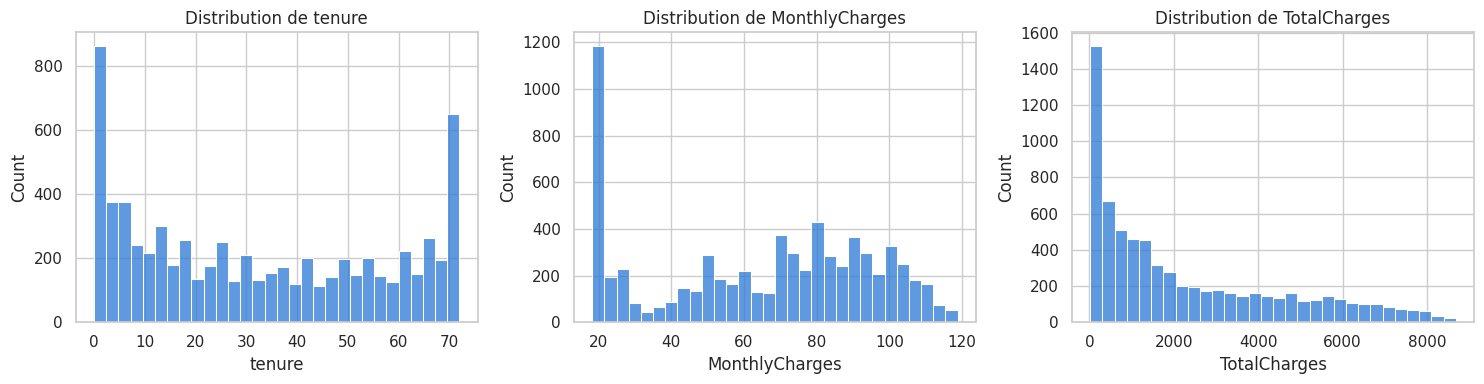

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var in zip(axes, VAR_NUM):
    sns.histplot(data=eda, x=var, bins=30, ax=ax, color="#2a78d6")
    ax.set_title(f"Distribution de {var}")
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "eda_distributions_numeriques.png", dpi=150)
plt.show()

**Observations :**
- `tenure` a deux pics : beaucoup de **nouveaux clients** (0–2 mois) et beaucoup de
  **clients très fidèles** (~70–72 mois, le maximum). Entre les deux, la répartition est assez plate.
- `MonthlyCharges` présente un grand pic autour de **20 \$** : ce sont presque tous des
  clients sans internet (92 % des clients payant moins de 30 \$ n'ont pas d'internet).
  Les autres clients se répartissent surtout entre 70 et 105 \$.
- `TotalCharges` est fortement **asymétrique à droite** : beaucoup de petits montants,
  peu de très grands. Cela confirme l'écart moyenne/médiane vu en section 1.

### 2.2 Comparaison entre clients restés et partis

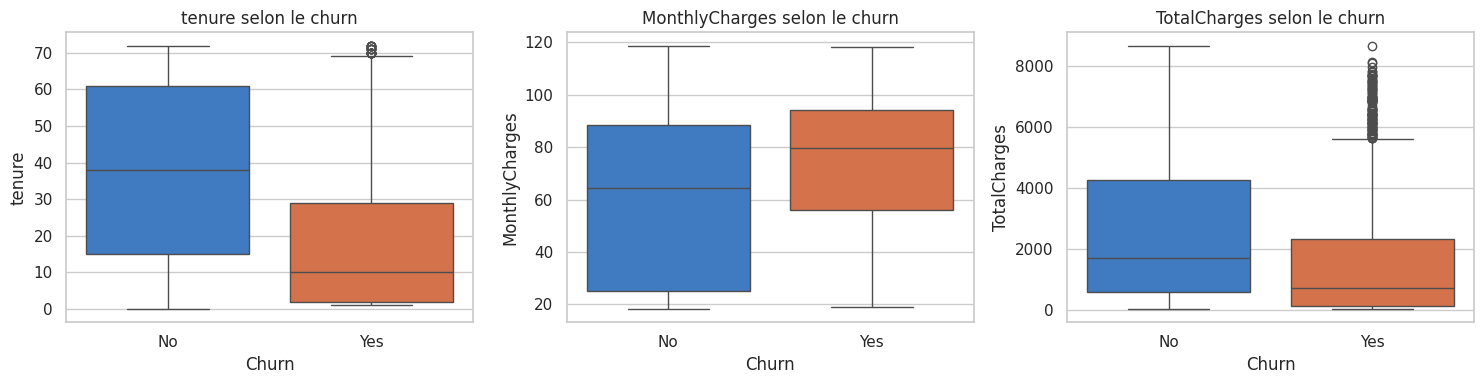

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.43,1683.60
Yes,10.0,79.65,703.55


In [7]:
COULEURS = {"No": "#2a78d6", "Yes": "#eb6834"}   # bleu = restés, orange = partis

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var in zip(axes, VAR_NUM):
    sns.boxplot(data=eda, x="Churn", y=var, hue="Churn", palette=COULEURS, legend=False, ax=ax)
    ax.set_title(f"{var} selon le churn")
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "eda_boxplots_par_churn.png", dpi=150)
plt.show()

eda.groupby("Churn")[VAR_NUM].median().round(2)

In [8]:
# Taux de churn par tranche d'ancienneté et par tranche de facture mensuelle
tranches_tenure = pd.cut(eda["tenure"], bins=[-1, 12, 24, 48, 72],
                         labels=["0-12 mois", "13-24 mois", "25-48 mois", "49-72 mois"])
tranches_factures = pd.cut(eda["MonthlyCharges"], bins=[0, 35, 70, 90, 120],
                           labels=["≤ 35 $", "35-70 $", "70-90 $", "> 90 $"])

print("Taux de churn par ancienneté (%) :")
print((eda.groupby(tranches_tenure, observed=True)["Churn_num"].mean() * 100).round(1))
print("\nTaux de churn par facture mensuelle (%) :")
print((eda.groupby(tranches_factures, observed=True)["Churn_num"].mean() * 100).round(1))

Taux de churn par ancienneté (%) :
tenure
0-12 mois     47.4
13-24 mois    28.7
25-48 mois    20.4
49-72 mois     9.5
Name: Churn_num, dtype: float64

Taux de churn par facture mensuelle (%) :
MonthlyCharges
≤ 35 $     10.9
35-70 $    23.9
70-90 $    37.8
> 90 $     32.8
Name: Churn_num, dtype: float64


**Observations :**
- **Ancienneté (`tenure`)** : c'est la différence la plus nette. Les clients partis ont
  une ancienneté médiane de **10 mois**, contre **38 mois** pour ceux qui restent.
  Le taux de churn est de **47,4 %** la première année, puis baisse régulièrement
  jusqu'à **9,5 %** après 4 ans. Le risque de départ est donc concentré sur les nouveaux clients.
- **Facture mensuelle (`MonthlyCharges`)** : les clients partis paient plus cher
  (médiane **79,65 \$** contre **64,43 \$**). Le churn passe de **10,9 %** pour les
  factures ≤ 35 \$ à **37,8 %** entre 70 et 90 \$.
- **Montant total (`TotalCharges`)** : il est plus faible chez les partis (médiane
  **703,55 \$** contre **1 683,60 \$**). Ce n'est pas un effet indépendant : comme
  `TotalCharges` ≈ `tenure` × `MonthlyCharges`, des clients partis tôt ont
  mécaniquement payé moins au total. À vérifier dans l'analyse des corrélations.
- **Valeurs éloignées** : les points isolés du groupe « Yes » (`tenure` et
  `TotalCharges` élevés) sont des clients anciens qui sont partis quand même.
  Ce sont des valeurs réelles et plausibles, pas des erreurs : on ne les supprime pas.

## 3. Analyse des variables catégorielles

Pour chaque variable, on compare le taux de churn de ses modalités au taux global
(26,5 %, ligne pointillée). Plus les barres sont différentes, plus la variable
est liée au churn.

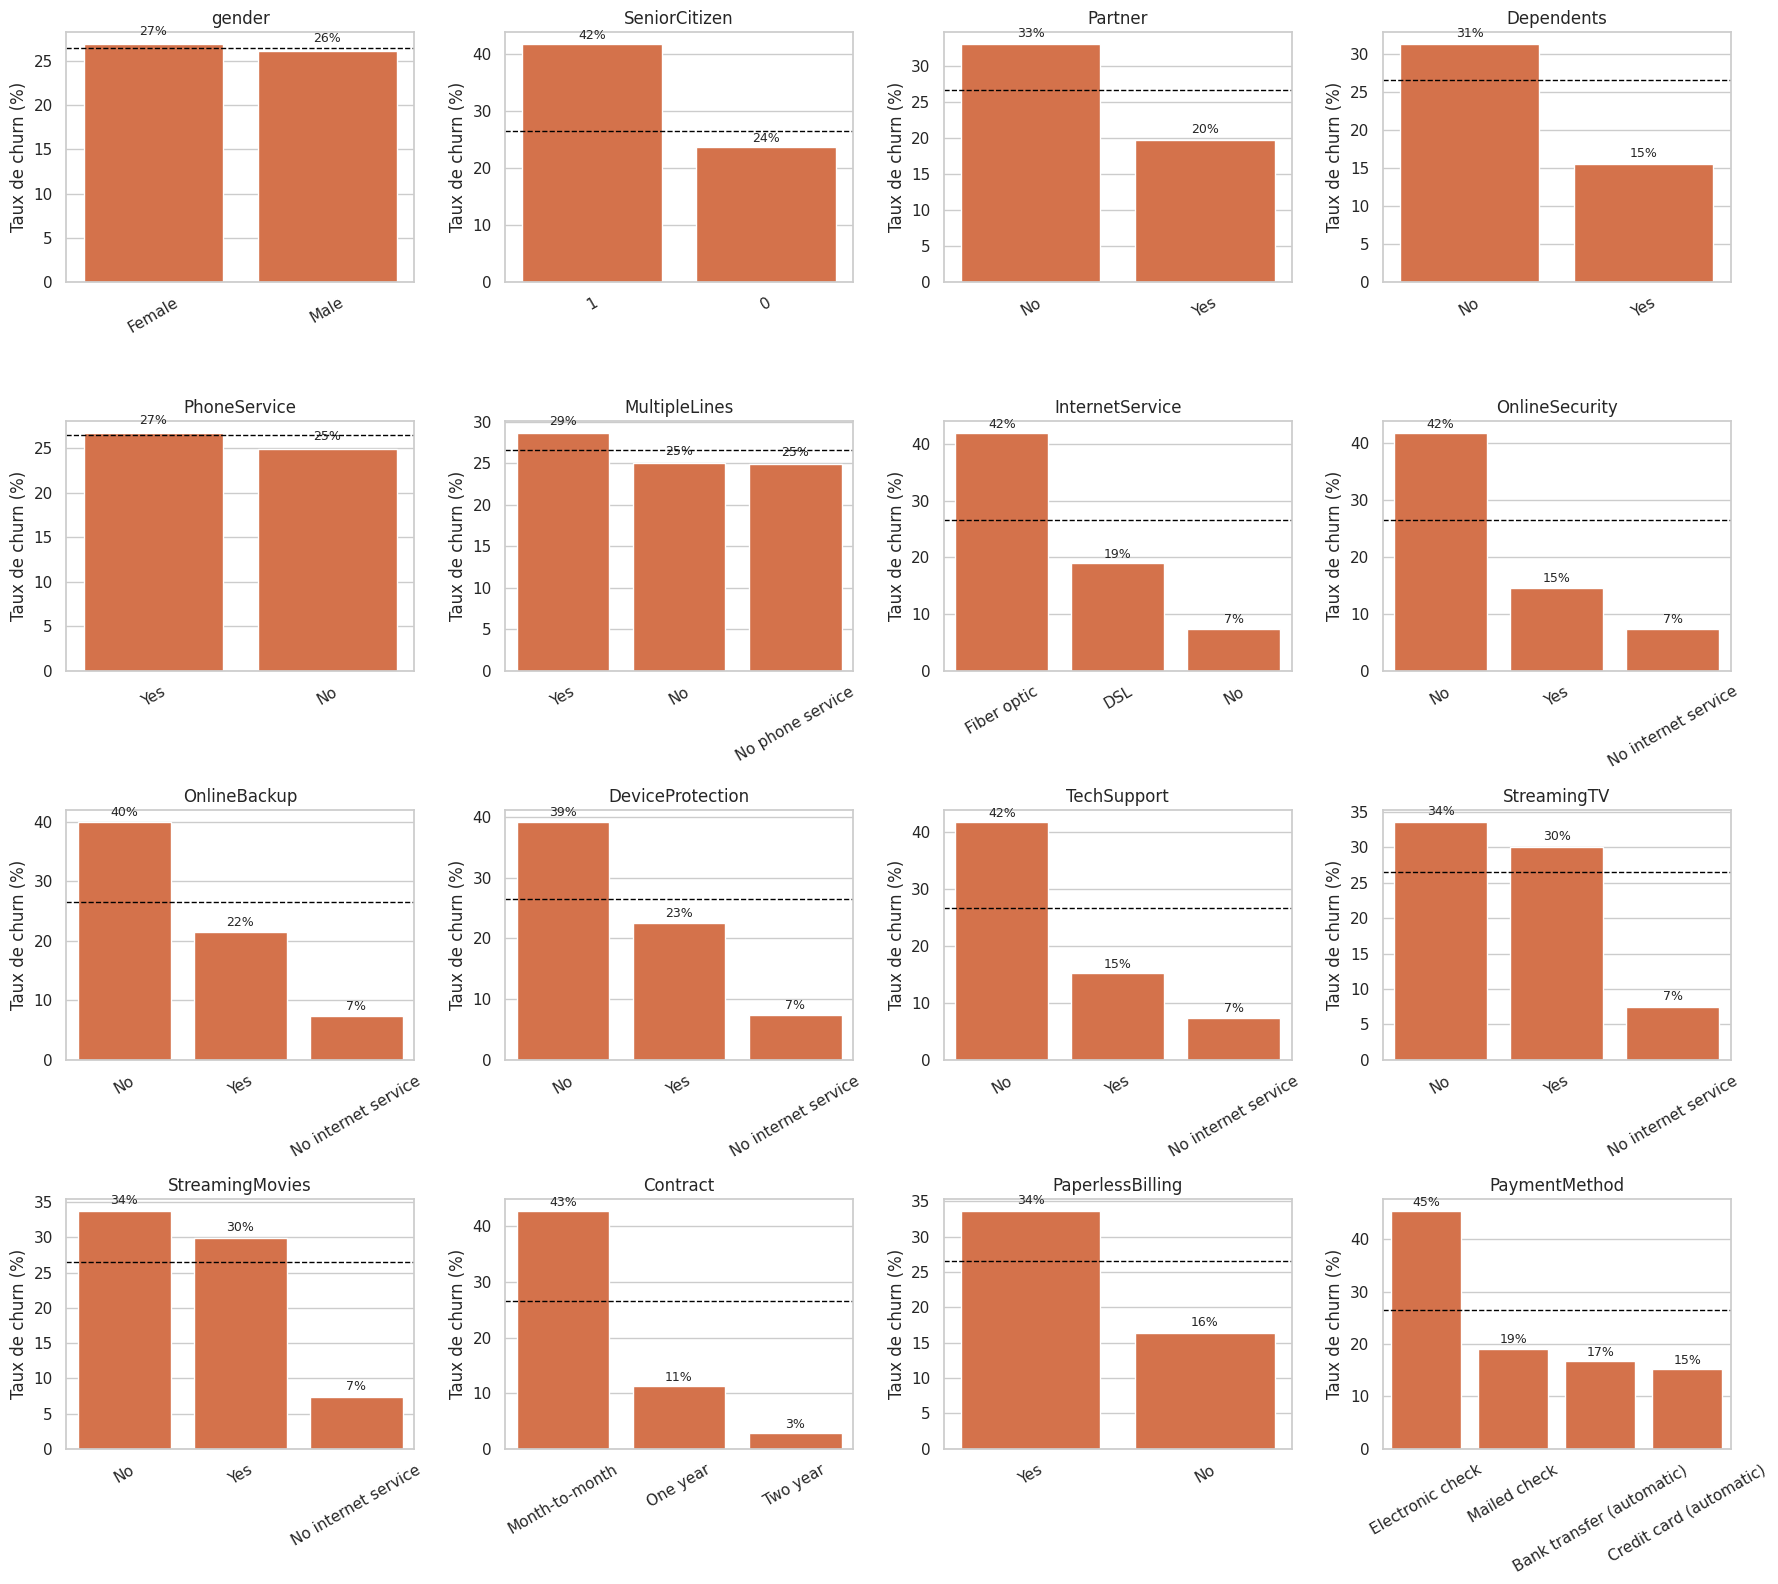

In [9]:
taux_global = eda["Churn_num"].mean() * 100

fig, axes = plt.subplots(4, 4, figsize=(18, 16))
for ax, var in zip(axes.flatten(), VAR_CAT):
    taux = (eda.groupby(var)["Churn_num"].mean() * 100).sort_values(ascending=False)
    sns.barplot(x=taux.index.astype(str), y=taux.values, ax=ax, color="#eb6834")
    ax.axhline(taux_global, color="black", linestyle="--", linewidth=1)
    ax.set_title(var)
    ax.set_xlabel("")
    ax.set_ylabel("Taux de churn (%)")
    ax.tick_params(axis="x", rotation=30)
    for i, v in enumerate(taux.values):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "eda_taux_churn_categorielles.png", dpi=110)
plt.show()

In [10]:
resume = []
for var in VAR_CAT:
    taux = eda.groupby(var)["Churn_num"].mean() * 100
    resume.append({
        "variable": var,
        "modalité la plus à risque": taux.idxmax(),
        "taux max (%)": round(taux.max(), 1),
        "modalité la moins à risque": taux.idxmin(),
        "taux min (%)": round(taux.min(), 1),
        "écart (points)": round(taux.max() - taux.min(), 1),
    })

resume = pd.DataFrame(resume).sort_values("écart (points)", ascending=False).reset_index(drop=True)
resume

,variable,modalité la plus à risque,taux max (%),modalité la moins à risque,taux min (%),écart (points)
0,Contract,Month-to-month,42.7,Two year,2.8,39.9
1,InternetService,Fiber optic,41.9,No,7.4,34.5
2,OnlineSecurity,No,41.8,No internet service,7.4,34.4
3,TechSupport,No,41.6,No internet service,7.4,34.2
4,OnlineBackup,No,39.9,No internet service,7.4,32.5
5,DeviceProtection,No,39.1,No internet service,7.4,31.7
6,PaymentMethod,Electronic check,45.3,Credit card (automatic),15.2,30.0
7,StreamingMovies,No,33.7,No internet service,7.4,26.3
8,StreamingTV,No,33.5,No internet service,7.4,26.1
9,SeniorCitizen,1,41.7,0,23.6,18.1


**Observations :**

*Variables fortement liées au churn :*
- **Type de contrat (`Contract`)** : c'est la variable la plus discriminante.
  Le churn atteint **42,7 %** pour les contrats mensuels, contre **11,3 %** (1 an)
  et seulement **2,8 %** (2 ans). Or les contrats mensuels concernent **55 %** des clients.
- **Internet (`InternetService`)** : les clients **fibre optique** partent beaucoup plus
  (**41,9 %**) que les clients DSL (19,0 %) ou sans internet (7,4 %).
- **Services d'accompagnement** : les clients *sans* sécurité en ligne (41,8 %),
  *sans* support technique (41,6 %), *sans* sauvegarde (39,9 %) ou *sans* protection
  de l'appareil (39,1 %) partent environ deux fois plus que ceux qui en ont (15 à 23 %).
- **Moyen de paiement (`PaymentMethod`)** : le **chèque électronique** a le taux le plus
  élevé de tout le dataset (**45,3 %**), contre 15 à 19 % pour les autres moyens.

*Variables moyennement liées :*
- Clients seniors : 41,7 % contre 23,6 %.
- Facturation sans papier (`PaperlessBilling = Yes`) : 33,6 % contre 16,3 %.
- Clients sans partenaire (33,0 % contre 19,7 %) ou sans personne à charge (31,3 % contre 15,5 %).

*Variables peu ou pas liées :*
- `gender` (26,9 % contre 26,2 %), `PhoneService` et `MultipleLines` : écarts de moins
  de 4 points, très proches du taux global.
- `StreamingTV` et `StreamingMovies` : peu de différence entre clients abonnés ou non
  (environ 30 % contre 34 %).

*Point technique :* la modalité « No internet service » a exactement le même taux
(7,4 %) dans les 6 variables de services, car ce sont les mêmes 1 526 clients.
Cette information est déjà contenue dans `InternetService = No` : il y a une
**redondance** à signaler au prétraitement (Membre 3).

Conséquence : pour ces 6 variables, l'écart du tableau est gonflé par cette modalité.
La comparaison pertinente est entre « Yes » et « No » : elle reste forte pour la sécurité
en ligne (14,6 % contre 41,8 %) ou le support technique (15,2 % contre 41,6 %), mais
faible pour le streaming (environ 30 % contre 34 %), d'où son classement parmi les variables peu liées.

⚠️ Ces écarts montrent une **association**, pas une cause. Certaines variables peuvent
se recouper (par exemple, les mêmes clients peuvent avoir un contrat mensuel et
payer par chèque électronique) : c'est aux modèles de démêler ces effets.